# Análise Exploratória de Dados do Spotify

## 1. Sobre o projeto

Este projeto tem como objetivo explorar dados de músicas disponíveis no Spotify e em outras plataformas de streaming, buscando identificar características associadas ao volume de reproduções (*streams*).

A proposta é utilizar técnicas de Análise Exploratória de Dados (EDA), estatística descritiva e testes estatísticos para investigar padrões de popularidade musical e responder a perguntas relevantes para o negócio.

Além da análise técnica, o projeto busca transformar os resultados em informações que possam apoiar decisões relacionadas à distribuição de músicas, presença em playlists e estratégias de divulgação no mercado musical.

## 2. Objetivos de negócio

A análise foi estruturada a partir das seguintes perguntas:

1. Músicas presentes em mais playlists do Spotify apresentam maior volume de streams?
2. A presença de uma música em diferentes plataformas de streaming está associada ao seu volume de reproduções?
3. Características das músicas, como quantidade de artistas, gênero musical e país, apresentam relação com o volume de streams?
4. O momento de lançamento da música (ano e mês) influencia o volume de streams acumulado?

## 3. Preparação do ambiente, carregamento e análise exploratória

### 3.1 Instalação e imports de Bibliotecas 

In [0]:
# Importação das Bibliotecas 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


### 3.2 Carregamento dos dados 

In [0]:
#Dados 
# Carregamento dos arquivos CSV

caminho_arquivo_um  = "/Volumes/workspace/crm_propensao/dados_fonte/track_in_competition _ativa_BR - track_in_competition _ativa_BR.csv"

caminho_arquivo_dois = "/Volumes/workspace/crm_propensao/dados_fonte/track_in_spotify_ativa_BR - track_in_spotify_ativa_BR.csv"

In [0]:
df1 = pd.read_csv(caminho_arquivo_um)
df2 = pd.read_csv(caminho_arquivo_dois)

### 3.3 Análise Exploratória dos dados 

In [0]:
df1.head()

,track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts
0,4082370,43,263,45,10,826
1,6247887,48,126,58,14,382
2,6974739,94,207,91,14,949
3,2362023,116,207,125,12,548
4,4386478,84,133,87,15,425


In [0]:
df2.head()

,track_id,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
0,4082370,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,Pop,South Korea,2023,7,14,553,147.0,141381703
1,6247887,LALA,Myke Towers,1,Reggaeton,Puerto Rico,2023,3,23,1474,48.0,133716286
2,6974739,vampire,Olivia Rodrigo,1,Pop,United States,2023,6,30,1397,113.0,140003974
3,2362023,Cruel Summer,Taylor Swift,1,Pop,United States,2019,8,23,7858,100.0,800840817
4,4386478,WHERE SHE GOES,Bad Bunny,1,Latin trap,PR,2023,5,18,3133,50.0,303236322


In [0]:
# Análise do tipo de dados 
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   track_id             953 non-null    object
 1   in_apple_playlists   953 non-null    int64 
 2   in_apple_charts      953 non-null    int64 
 3   in_deezer_playlists  953 non-null    object
 4   in_deezer_charts     953 non-null    int64 
 5   in_shazam_charts     903 non-null    object
dtypes: int64(3), object(3)
memory usage: 44.8+ KB


In [0]:
#Análise do tipo de dados

df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 843 entries, 0 to 842
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_id              843 non-null    int64  
 1   track_name            843 non-null    object 
 2   artists_name          843 non-null    object 
 3   artist_count          843 non-null    int64  
 4   main_music_genre      842 non-null    object 
 5   main_country          842 non-null    object 
 6   released_year         843 non-null    int64  
 7   released_month        843 non-null    int64  
 8   released_day          843 non-null    int64  
 9   in_spotify_playlists  843 non-null    object 
 10  in_spotify_charts     839 non-null    float64
 11  streams               843 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 79.2+ KB


In [0]:
#Análise de valores nulos 

df1.isnull().sum()
df2.isnull().sum()

track_id                0
track_name              0
artists_name            0
artist_count            0
main_music_genre        1
main_country            1
released_year           0
released_month          0
released_day            0
in_spotify_playlists    0
in_spotify_charts       4
streams                 0
dtype: int64

In [0]:
# Linhas duplicadas 
print("Duplicatas no arquivo 1", df1.duplicated().sum())
print("Duplicatas no arquivo 2", df2.duplicated().sum())

Duplicatas no arquivo 1 0
Duplicatas no arquivo 2 4


In [0]:
#Quantidade de linhas duplicadas em cada arquivo

print("Duplicatas no arquivo 1:", df1.duplicated().sum())
print("Duplicatas no arquivo 2:", df2.duplicated().sum())

Duplicatas no arquivo 1: 0
Duplicatas no arquivo 2: 4


In [0]:
#Visualizar as linhas duplicadas do arquivo 2 (df2)
duplicatas_df2 = df2[df2.duplicated(keep=False)]

display(duplicatas_df2)

track_id,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
4322356,Privileged Rappers,"Drake, 21 Savage",2,Heavy metal,Canada,2022,11,4,1007,0.0,112436403
4343383,The Astronaut,Jin,1,K-pop,South Korea,2022,10,28,481,9.0,203436468
3108815,BackOutsideBoyz,Drake,1,Heavy metal,Canada,2022,11,4,1045,0.0,93367537
8174233,Broke Boys,"Drake, 21 Savage",2,Heavy metal,Canada,2022,11,4,1060,0.0,106249219
4322356,Privileged Rappers,"Drake, 21 Savage",2,Heavy metal,Canada,2022,11,4,1007,0.0,112436403
4343383,The Astronaut,Jin,1,K-pop,South Korea,2022,10,28,481,9.0,203436468
3108815,BackOutsideBoyz,Drake,1,Heavy metal,Canada,2022,11,4,1045,0.0,93367537
8174233,Broke Boys,"Drake, 21 Savage",2,Heavy metal,Canada,2022,11,4,1060,0.0,106249219


In [0]:
# Não temos linhas duplicadas no arquivo 1 (df1). 

print("Linhas totais:", len(df1))
print("Linhas distintas:", len(df1.drop_duplicates()))

Linhas totais: 953
Linhas distintas: 953


In [0]:
#No arquivo 2(df2), temos segundo dataframe temos 4 linhas que aparecem duas vezes. Desse modo, vamos excluir as quatro linhas que se repetem. 

print("Linhas totais:", len(df2))
print("Linhas distintas:", len(df2.drop_duplicates()))

Linhas totais: 843
Linhas distintas: 839


In [0]:
# De acordo com a análise realizada até aqui, será necessário mudar o tipo das seguintes variáveis: 

# Uma linha possui track_id inválido ('0:00') — convertemos com coerce, removemos e depois convertemos para int

df1['track_id'] = pd.to_numeric(df1['track_id'], errors='coerce')
df1 = df1.dropna(subset=['track_id'])
df1['track_id'] = df1['track_id'].astype(int)


In [0]:
# A variável 'in_shazam_charts' possui valores nulos e texto com separador de milhar (ex.: '1,008')
# Removemos a vírgula e usamos coerce + Int64 (inteiro que aceita nulos, sem perder as linhas)
df1['in_shazam_charts'] = pd.to_numeric(
    df1['in_shazam_charts'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
).astype('Int64')

In [0]:
# A variável 'in_deezer_playlists' possui valores nulos e texto com separador de milhar (ex.: '1,008')
# Removemos a vírgula e usamos coerce + Int64 (inteiro que aceita nulos, sem perder as linhas)
df1['in_deezer_playlists'] = pd.to_numeric(df1['in_deezer_playlists'].astype(str).str.replace(',', '', regex=False), errors='coerce').astype('Int64')


In [0]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   track_id             952 non-null    int64
 1   in_apple_playlists   952 non-null    int64
 2   in_apple_charts      952 non-null    int64
 3   in_deezer_playlists  952 non-null    Int64
 4   in_deezer_charts     952 non-null    int64
 5   in_shazam_charts     902 non-null    Int64
dtypes: Int64(2), int64(4)
memory usage: 53.9 KB


In [0]:
# Tratamento das variáveis 'track_name', 'artists_name', 'main_music_genre' e, 'main_country' do segundo dataframe
# Usamos astype('string') (dtype moderno de texto) — com astype(str) o info() continuaria 
# mostrando 'object', pois é assim que o pandas armazena texto no dtype antigo

df2['track_name'] = df2['track_name'].astype('string')
df2['artists_name'] = df2['artists_name'].astype('string')
df2['main_music_genre'] = df2['main_music_genre'].astype('string')
df2['main_country'] = df2['main_country'].astype('string')


In [0]:
# Tratamento das variáveis 'in_spotfy_playlists' e, 'in_spotify_chats' do segundo dataframe
# Alguns registros possuem valores inválidos nessa coluna — convertemos com coerce,
# removemos as linhas problemáticas e depois convertemos para int

df2['in_spotify_playlists'] = pd.to_numeric(df2['in_spotify_playlists'], errors='coerce')
df2 = df2.dropna(subset=['in_spotify_playlists'])
df2['in_spotify_playlists'] = df2['in_spotify_playlists'].astype(int)

In [0]:
# A coluna possui valores nulos — usamos Int64 (inteiro que aceita nulos, sem perder as linhas)
# (também corrigimos o nome da coluna: era 'in_spotfy_charts')
df2['in_spotify_charts'] = df2['in_spotify_charts'].astype('Int64')

In [0]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 842 entries, 0 to 842
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   track_id              842 non-null    int64 
 1   track_name            842 non-null    string
 2   artists_name          842 non-null    string
 3   artist_count          842 non-null    int64 
 4   main_music_genre      841 non-null    string
 5   main_country          841 non-null    string
 6   released_year         842 non-null    int64 
 7   released_month        842 non-null    int64 
 8   released_day          842 non-null    int64 
 9   in_spotify_playlists  842 non-null    int64 
 10  in_spotify_charts     838 non-null    Int64 
 11  streams               842 non-null    int64 
dtypes: Int64(1), int64(7), string(4)
memory usage: 86.3 KB


### 3.4 Junção dos dois DataFrames com join



In [0]:
df = df1.merge(df2, on='track_id', how='inner')

In [0]:
df.head()

,track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
0,4082370,43,263,45,10,826,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,Pop,South Korea,2023,7,14,553,147,141381703
1,6247887,48,126,58,14,382,LALA,Myke Towers,1,Reggaeton,Puerto Rico,2023,3,23,1474,48,133716286
2,6974739,94,207,91,14,949,vampire,Olivia Rodrigo,1,Pop,United States,2023,6,30,1397,113,140003974
3,2362023,116,207,125,12,548,Cruel Summer,Taylor Swift,1,Pop,United States,2019,8,23,7858,100,800840817
4,4386478,84,133,87,15,425,WHERE SHE GOES,Bad Bunny,1,Latin trap,PR,2023,5,18,3133,50,303236322


In [0]:
# Mapa do calor: visualização das correlações entre as variáveis numéricas do seu conjunto de dados. 

# Selecionar apenas as colunas numéricas
df_numerico = df.select_dtypes(include='number')

# Visualizar as colunas selecionadas
print(df_numerico.columns.tolist())

['track_id', 'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists', 'in_deezer_charts', 'in_shazam_charts', 'artist_count', 'released_year', 'released_month', 'released_day', 'in_spotify_playlists', 'in_spotify_charts', 'streams']


In [0]:
# Calcular a matriz de correlação (excluindo track_id, que é apenas um identificador)
matriz_correlacao = df_numerico.drop(columns=['track_id']).corr(method='pearson')

# Visualizar a matriz
display(matriz_correlacao)

in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
1.0,0.41942816726930326,0.4745921036564923,0.36105261509175707,0.159991267939973,-0.03996571018005049,-0.22803605784545244,-0.020850839884899736,0.03123720397679025,0.7125949849462725,0.23483389874884875,0.7753163467798503
0.41942816726930326,1.0,0.1709042087737321,0.387116772987539,0.43879395526648807,-0.06063659152884604,-0.05425693433198855,-0.031934295710328145,0.02125820777131511,0.2683457375322426,0.5549611152899815,0.3176823622228646
0.4745921036564923,0.1709042087737321,1.0,0.06447940789759211,0.0727097962002677,-0.06311450000462406,-0.32579811490768124,-0.10199287291560587,-0.08578888300605023,0.8279258719907472,0.08609353173242335,0.5992366060469033
0.36105261509175707,0.387116772987539,0.06447940789759211,1.0,0.45490051549585725,0.017114099213726617,0.09402688291724741,-0.011557928661246997,0.07269484796391117,0.14051161755255143,0.6071930083075832,0.22899543120354882
0.159991267939973,0.43879395526648807,0.0727097962002677,0.45490051549585725,1.0,-0.004243683718986091,0.018188331353640997,-0.1045843435153508,0.030947094764932827,0.07625812470745806,0.6097492132228517,0.02035380256480413
-0.03996571018005049,-0.06063659152884604,-0.06311450000462406,0.017114099213726617,-0.004243683718986091,1.0,0.09360453491415024,0.051309959699505615,-0.06512342957763664,-0.08580733146739335,0.0038337115151357713,-0.12310951157487161
-0.22803605784545244,-0.05425693433198855,-0.32579811490768124,0.09402688291724741,0.018188331353640997,0.09360453491415024,1.0,0.08238817625643628,0.15972115959650351,-0.41716234436737737,0.06846076216796862,-0.24118179023355216
-0.020850839884899736,-0.031934295710328145,-0.10199287291560587,-0.011557928661246997,-0.1045843435153508,0.051309959699505615,0.08238817625643628,1.0,0.0789350354789796,-0.12794973938335125,-0.05805685946106606,-0.0447462486498561
0.03123720397679025,0.02125820777131511,-0.08578888300605023,0.07269484796391117,0.030947094764932827,-0.06512342957763664,0.15972115959650351,0.0789350354789796,1.0,-0.07965921719384438,0.02177636439612442,0.017749147766256617
0.7125949849462725,0.2683457375322426,0.8279258719907472,0.14051161755255143,0.07625812470745806,-0.08580733146739335,-0.41716234436737737,-0.12794973938335125,-0.07965921719384438,1.0,0.15959790935624021,0.7885423771559363


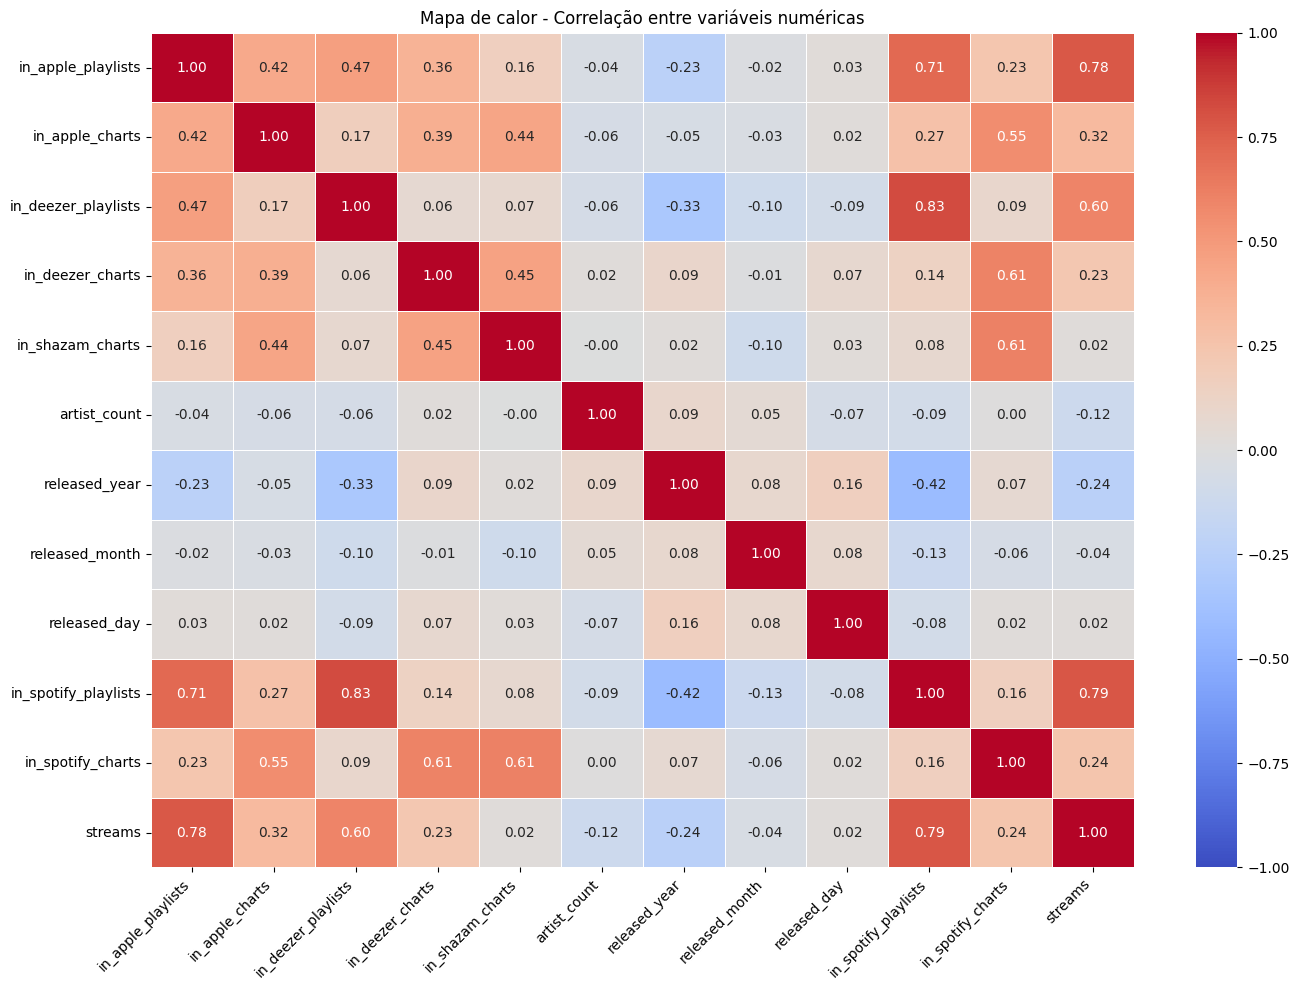

In [0]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Mapa de calor - Correlação entre variáveis numéricas')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

De acordo com o mapa de calor de Sperman, encontramos uma correlação forte entre as variáveis: 
- streams x in_spotfy_playlist = 0.79.
- streams x in_apple_playlist = 0.79.
- streams x in_deezer_playlist =0.60.

Vericamos que não existe uma correlação forte entre strems e o ranking das músicas nas respectivas plataformas (_chats), tampouco correlação forte entre o mês e o dia do lançamento da música: 
- streams x in_apple_charts = 0.32. 
- streams x in_deezer_chats = 0.23.
- streams x in_shazam_chars = 0.02.
- streams x in_spotfy_chats = 0.24.
- streams x realeased_month = -0.04.
- stream x realesed_day = 0.02.
- streams x released_year = -0.24.

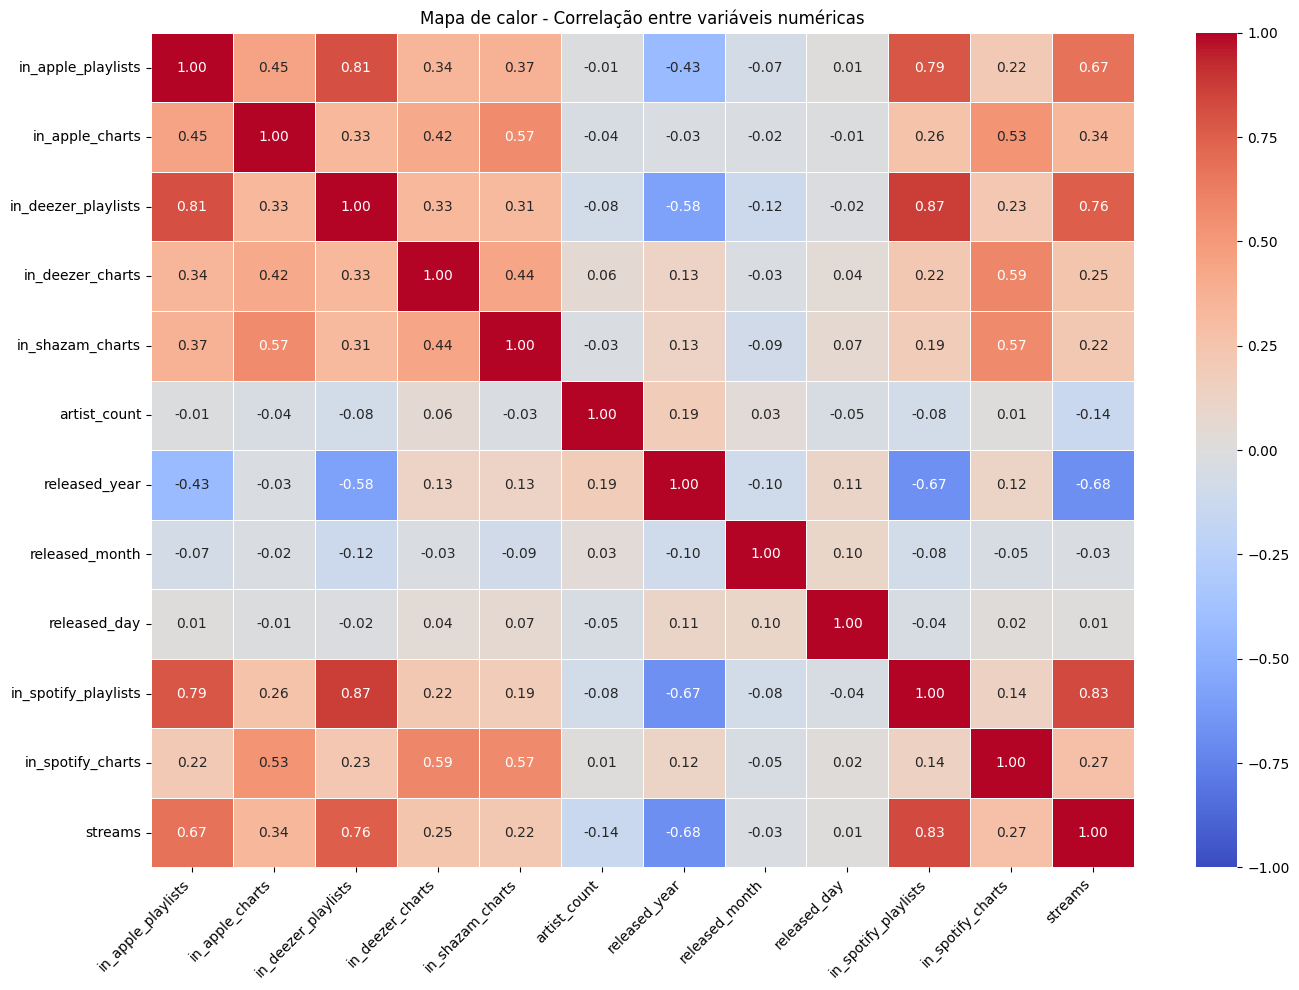

In [0]:
# Calcular a matriz de correlação (excluindo track_id, que é apenas um identificador)
matriz_correlacao_spearman = df_numerico.drop(columns=['track_id']).corr(method='spearman')

plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_correlacao_spearman,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Mapa de calor - Correlação entre variáveis numéricas')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

De acordo com o mapa de calor de Sperman, encontramos uma correlação forte entre as variáveis: 
- streams x in_spotfy_playlist = 0.83.
- streams x in_apple_playlist = 0.79.
- streams x in_deezer_playlist =0.87.
- streams x released_year = -0.68.

Vericamos que não existe uma correlação forte entre strems e o ranking das músicas nas respectivas plataformas (_chats), tampouco correlação forte entre o mês e o dia do lançamento da música: 
- streams x in_apple_charts = 0.34. 
- streams x in_deezer_chats = 0.25.
- streams x in_shazam_chars = 0.22.
- streams x in_spotfy_chats = 0.27.
- streams x realeased_month = -0.03.
- stream x realesed_day = 0.01.





### Escolha do método de correlação

Para investigar a associação entre a quantidade de playlists e o volume de streams, foram utilizados os coeficientes de correlação de Pearson e Spearman.

O coeficiente de Pearson avalia a intensidade e a direção de uma relação linear entre duas variáveis numéricas. Já o coeficiente de Spearman utiliza a ordenação dos valores (*ranks*) e permite identificar associações monotônicas, mesmo quando não existe uma relação linear.

Considerando as características do conjunto de dados, especialmente a assimetria na distribuição de streams e a presença de valores extremos, o coeficiente de Spearman foi considerado mais adequado como referência principal para a interpretação dos resultados.

A análise entre a quantidade de playlists do Spotify e o volume de streams apresentou correlação de Pearson de 0,79 e de Spearman de 0,83.

Ambos os resultados indicaram uma forte associação positiva. O resultado de Spearman reforça que músicas com posições mais elevadas em quantidade de playlists tendem também a apresentar posições mais elevadas em volume de streams.

Essa associação não estabelece uma relação de causalidade, pois a popularidade da música também pode influenciar sua inclusão em playlists.

### 4. Perguntas do negócio 

#### 4.1 Análise da relação entre playlist e streams

Após a análise e tratamento dos dados, vamos às perguntas de negócio. 

1. Músicas presentes em mais playlists do Spotify apresentam maior volume de streams?

Hipótese Inicial: 

H1: Quanto maior a quantidade de playlists do Spotfy em que uma música está presente, maior tende a ser seu volume de streams. 

Hipótese Contrária:

H0: Não existe uma relação significativa entre a quantidade de playlists e o volume de streams. 



In [0]:
#Variáveis analisadas: in_spotify_playlists, streams. 
#Remover registros sem informações na variáveis analisadas. 

df_analise = df.dropna(subset = ['in_spotify_playlists', 'streams']).copy()

df_analise.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 842 entries, 0 to 841
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   track_id              842 non-null    int64 
 1   in_apple_playlists    842 non-null    int64 
 2   in_apple_charts       842 non-null    int64 
 3   in_deezer_playlists   842 non-null    Int64 
 4   in_deezer_charts      842 non-null    int64 
 5   in_shazam_charts      794 non-null    Int64 
 6   track_name            842 non-null    string
 7   artists_name          842 non-null    string
 8   artist_count          842 non-null    int64 
 9   main_music_genre      841 non-null    string
 10  main_country          841 non-null    string
 11  released_year         842 non-null    int64 
 12  released_month        842 non-null    int64 
 13  released_day          842 non-null    int64 
 14  in_spotify_playlists  842 non-null    int64 
 15  in_spotify_charts     838 non-null    In

In [0]:
df_analise[['in_spotify_playlists', 'streams']].describe().T

,count,mean,std,min,25%,50%,75%,max
in_spotify_playlists,842.0,5.520545e+03,8.267973e+03,31.0,896.0,2310.5,6.070500e+03,5.289800e+04
streams,842.0,5.346673e+08,5.845274e+08,2762.0,146504598.0,300308786.5,7.019978e+08,3.703895e+09


### Análise de correlação: playlists e streams

De acordo com os mapas de calor, foi identificada uma forte associação positiva entre a quantidade de playlists em que uma música está presente no Spotify e seu número de streams.

O coeficiente de correlação de Pearson foi de **0,7885**, indicando uma forte relação linear positiva. Já o coeficiente de Spearman foi de **0,8291**, reforçando a existência de uma associação positiva entre as variáveis, considerando também seus rankings.

Os resultados sugerem que músicas presentes em um maior número de playlists tendem a apresentar maior volume de streams. Entretanto, a correlação não implica causalidade, não sendo possível afirmar que a inclusão em playlists, isoladamente, seja responsável pelo aumento das reproduções.



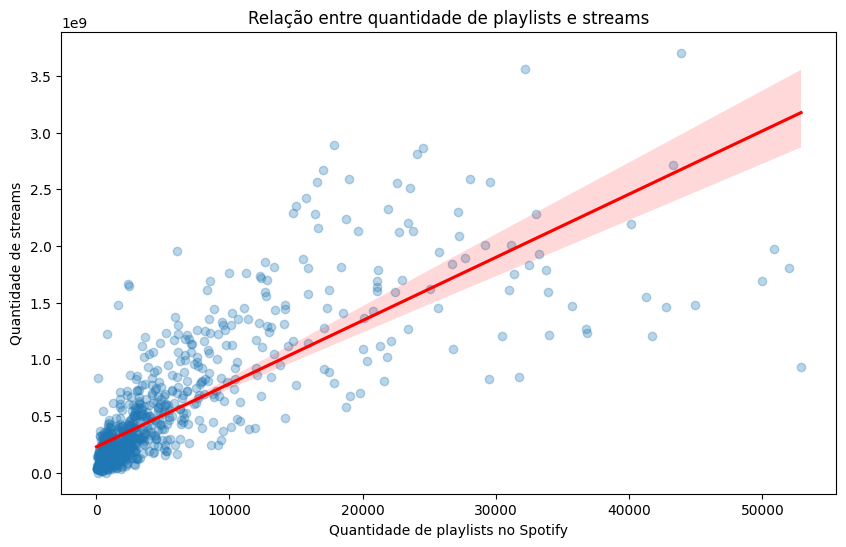

In [0]:
plt.figure(figsize=(10, 6))

sns.regplot(data = df_analise, 
            x = 'in_spotify_playlists', 
            y = 'streams',
            scatter_kws = {'alpha':0.3},
            line_kws = {'color': 'red'})


plt.title('Relação entre quantidade de playlists e streams')
plt.xlabel('Quantidade de playlists no Spotify')
plt.ylabel('Quantidade de streams')

plt.show()

Desse modo, podemos dizer que sim, existe uma correlação forte entre a quantidade de playlists que a música está presente e a quantidade de streams. 

#### 4.4 Análise de correlação. Músicas que entram nos charts (rankings) do Spotify têm mais streams que as que não entram?

Pelo mapa de calor, temos que a correlação de Pearson entre ranking do Spotfy e streams é de 0.24 e a de Spearman é de 0.27. Desse modo, não podemos dizer que as músicas que entram no charts do Spotfy tem mais streams que as que não entram. 

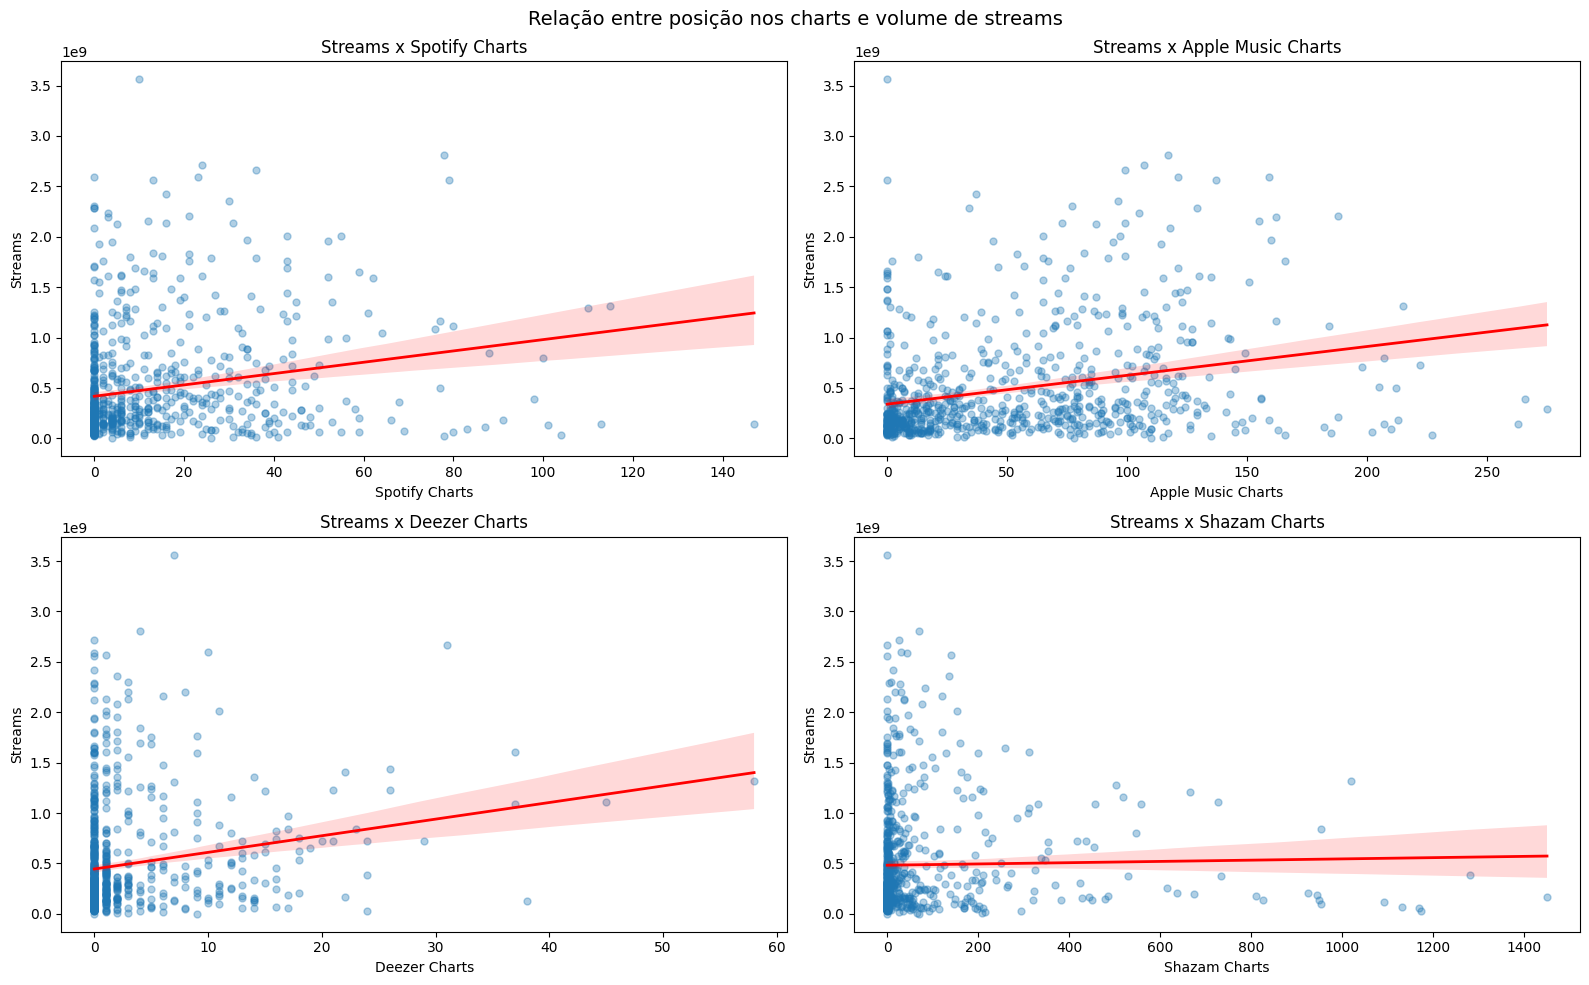

In [0]:
# Gráficos de dispersão: variáveis de charts (rankings) x streams

colunas_charts = [
    'in_spotify_charts',
    'in_apple_charts',
    'in_deezer_charts',
    'in_shazam_charts'
]

# Remover registros sem informações nas variáveis analisadas
df_analise_charts = df.dropna(subset=colunas_charts + ['streams']).copy()

# Criar figura com quatro subplots (2 linhas x 2 colunas)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Achatar os eixos para facilitar a iteração
axes = axes.flatten()

titulos = [
    'Spotify Charts',
    'Apple Music Charts',
    'Deezer Charts',
    'Shazam Charts'
]

# Gerar os gráficos
for ax, coluna, titulo in zip(axes, colunas_charts, titulos):
    sns.regplot(
        data=df_analise_charts,
        x=coluna,
        y='streams',
        ax=ax,
        scatter_kws={'alpha': 0.35, 's': 25},
        line_kws={'color': 'red', 'linewidth': 2}
    )
    ax.set_title(f'Streams x {titulo}')
    ax.set_xlabel(titulo)
    ax.set_ylabel('Streams')

plt.suptitle('Relação entre posição nos charts e volume de streams', fontsize=14)
plt.tight_layout()

plt.show()

#### 4.3 Análise de correlação.  Existe relação entre presença em múltiplas plataformas (Spotify, Apple Music, Deezer, Shazam) e volume de streams — ou seja, o sucesso é "global" ou específico de plataforma?

In [0]:
# Definir as colunas das plataformas
colunas_plataformas = [
    'in_spotify_playlists',
    'in_apple_playlists',
    'in_deezer_playlists' 
]

df_analise_playlist = df.dropna(
    subset = colunas_plataformas + ['streams']     
).copy()

#Criar indicadores de presença
for coluna in colunas_plataformas:
    df[coluna+ '_presente'] = (df[coluna] > 0).astype(int)
    
#Contar quantas plataformas a música está presente
colunas_presenca = [coluna + '_presente' for coluna in colunas_plataformas]

df['total_plataformas'] = (df[colunas_presenca].sum(axis = 1)
                           ) 

df[['streams', 'total_plataformas'] + colunas_presenca].head() 

,streams,total_plataformas,in_spotify_playlists_presente,in_apple_playlists_presente,in_deezer_playlists_presente
0,141381703,3,1,1,1
1,133716286,3,1,1,1
2,140003974,3,1,1,1
3,800840817,3,1,1,1
4,303236322,3,1,1,1


In [0]:
resultado = df.groupby('total_plataformas')['streams'].agg(
    qtd='count',
    media_Streams='mean',
    mediana_Streams='median',
    minimo_Streams='min',
    maximo_Streams='max'
).reset_index()

resultado

,total_plataformas,qtd,media_Streams,mediana_Streams,minimo_Streams,maximo_Streams
0,1,4,3.190966e+08,86604969.0,41210087,1061966512
1,2,31,3.118748e+08,139836056.0,34450974,1661187319
2,3,807,5.442942e+08,305650299.0,2762,3703895074


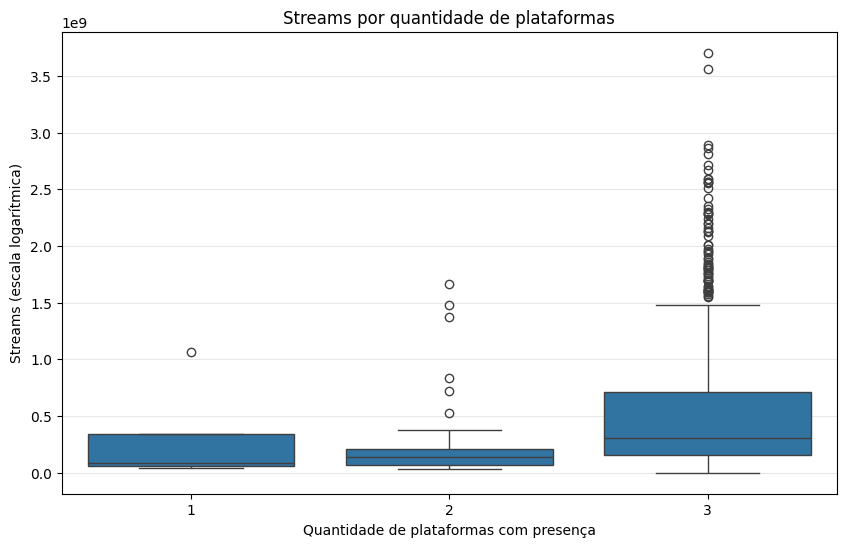

In [0]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='total_plataformas',
    y='streams'
)

#plt.yscale('log')

plt.title('Streams por quantidade de plataformas')
plt.xlabel('Quantidade de plataformas com presença')
plt.ylabel('Streams (escala logarítmica)')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [0]:
#Correlação entre a presença em cada plataforma e o volume de streams

colunas_correlacao = [
    'in_spotify_playlists',
    'in_apple_playlists',
    'in_deezer_playlists',
    'streams' 
]



correlacao = df[colunas_correlacao].corr(
    method='spearman'
)

correlacao

,in_spotify_playlists,in_apple_playlists,in_deezer_playlists,streams
in_spotify_playlists,1.000000,0.785874,0.868309,0.829068
in_apple_playlists,0.785874,1.000000,0.811310,0.672330
in_deezer_playlists,0.868309,0.811310,1.000000,0.757703
streams,0.829068,0.672330,0.757703,1.000000


In [0]:
#Correlação entre o número de plataformas presentes e os streams (spearman)

correlacao_global = df[
    ['total_plataformas', 'streams']
].corr(method='spearman')

print(correlacao_global)

                   total_plataformas  streams
total_plataformas            1.00000  0.13474
streams                      0.13474  1.00000


In [0]:
#Correlação entre o número de plataformas presentes e os streams (spearman)

correlacao_global2 = df[
    ['total_plataformas', 'streams']
].corr(method='pearson')

print(correlacao_global2)

                   total_plataformas  streams
total_plataformas            1.00000  0.07574
streams                      0.07574  1.00000


A análise da presença multiplataforma revelou uma correlação de Spearman de 0.13474 entre a quantidade de plataformas em que uma música está presente e seu volume de streams no Spotify. Esse resultado indica uma associação positiva muito fraca, sugerindo que a presença em múltiplas plataformas, isoladamente, não está fortemente relacionada ao desempenho de reproduções no Spotify.

Em contrapartida, a análise anterior identificou uma forte associação positiva entre a quantidade de playlists no Spotify e o volume de streams. Esse resultado sugere que a popularidade dentro do próprio ecossistema da plataforma apresenta uma relação mais expressiva com o volume de reproduções.

In [0]:
df.groupby('total_plataformas')['streams'].agg(
    quantidade='count',
    media='mean',
    mediana='median'
).reset_index()

,total_plataformas,quantidade,media,mediana
0,1,4,3.190966e+08,86604969.0
1,2,31,3.118748e+08,139836056.0
2,3,807,5.442942e+08,305650299.0


In [0]:
df['total_plataformas'].value_counts().sort_index()

total_plataformas
1      4
2     31
3    807
Name: count, dtype: int64

In [0]:
df[colunas_presenca].sum()

in_spotify_playlists_presente    842
in_apple_playlists_presente      820
in_deezer_playlists_presente     825
dtype: int64

In [0]:
# Vamos analisar se as músicas presentes simultaneamente na Apple Music e na Deezer e apresentam um comportamento diferente do Stream no Spotfy. 
# 
# Comparar streams entre músicas presentes e ausentes
# em cada plataforma

resultado_presenca = df.groupby(
    ['in_apple_playlists_presente',
     'in_deezer_playlists_presente']
)['streams'].agg(
    quantidade='count',
    media='mean',
    mediana='median'
).reset_index()

resultado_presenca

,in_apple_playlists_presente,in_deezer_playlists_presente,quantidade,media,mediana
0,0,0,4,3.190966e+08,86604969.0
1,0,1,18,4.090652e+08,132871693.5
2,1,0,13,1.773036e+08,166570053.0
3,1,1,807,5.442942e+08,305650299.0


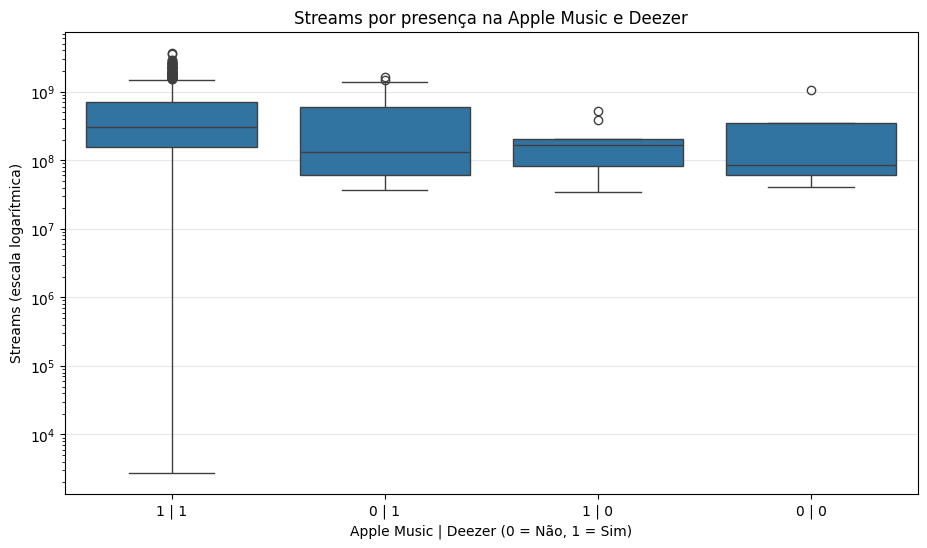

In [0]:

import seaborn as sns

df['grupo_plataformas'] = (
    df['in_apple_playlists_presente'].astype(str)
    + ' | '
    + df['in_deezer_playlists_presente'].astype(str)
)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='grupo_plataformas',
    y='streams'
)

plt.yscale('log')

plt.title('Streams por presença na Apple Music e Deezer')
plt.xlabel('Apple Music | Deezer (0 = Não, 1 = Sim)')
plt.ylabel('Streams (escala logarítmica)')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [0]:
colunas = [
    'in_spotify_playlists',
    'in_apple_playlists',
    'in_deezer_playlists',
    'streams'
]

df[colunas].corr(method='spearman')['streams'].sort_values(
    ascending=False
)

streams                 1.000000
in_spotify_playlists    0.829068
in_deezer_playlists     0.757703
in_apple_playlists      0.672330
Name: streams, dtype: float64

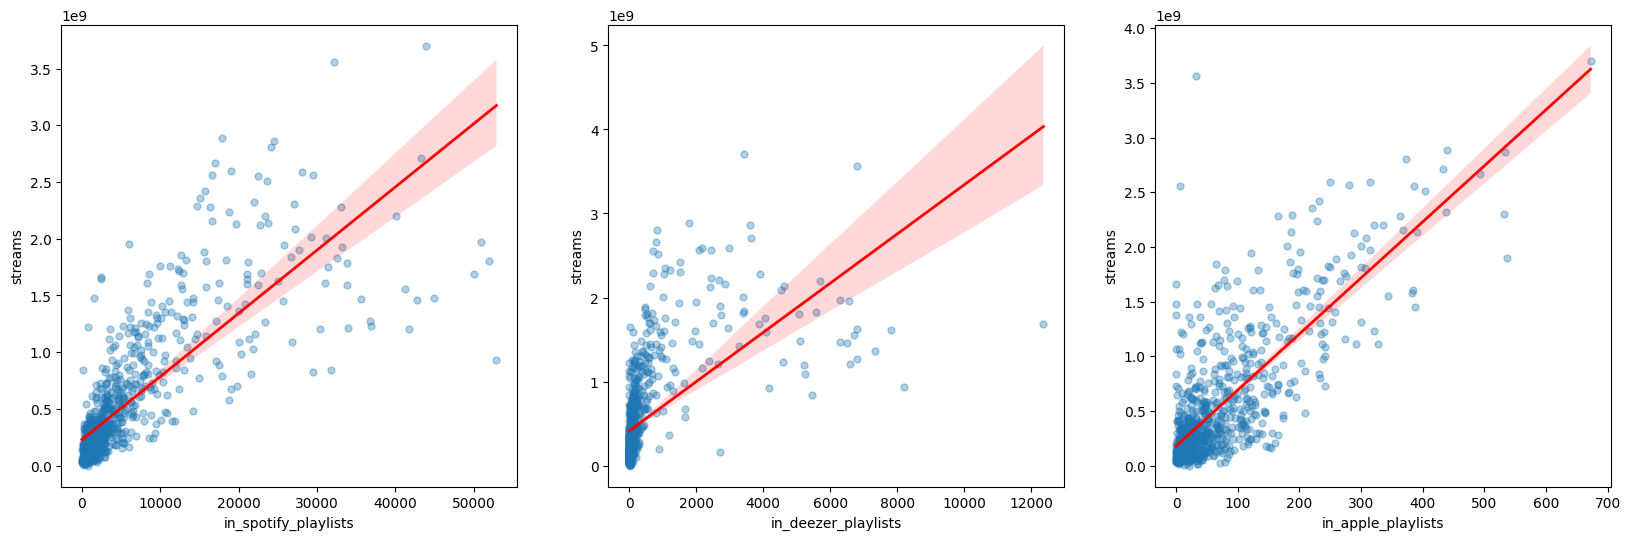

In [0]:

df_grafico = df[colunas].copy()

#Criar figura com três subplots
fig, axes = plt.subplots(1, 3, figsize = (20,6))

#Configurar as plataformas

plataformas = [
    ('in_spotify_playlists', 'Spotify'),
    ('in_deezer_playlists', 'Deezer'),
    ('in_apple_playlists', 'Apple Music')
]

#Gerar os gráficos

for ax, (coluna, plataforma) in zip(axes, plataformas):
    sns.regplot(
        data = df_grafico,
        x = coluna, 
        y = 'streams',
        ax = ax, 
        scatter_kws={'alpha': 0.35, 's': 25},
        line_kws={'color': 'red', 'linewidth': 2}
    )


A análise dos gráficos de dispersão e das correlações de Spearman identificou associações positivas entre a quantidade de playlists em que uma música está presente e seu volume de streams no Spotify.

A maior correlação foi observada para as playlists do próprio Spotify (0,829), seguida pelo Deezer (0,758) e pela Apple Music (0,672).

Os resultados sugerem que músicas com maior presença em playlists tendem a apresentar maior volume de reproduções no Spotify, inclusive quando essa presença ocorre em plataformas concorrentes.

Esse comportamento pode indicar que a popularidade das músicas se manifesta em diferentes serviços de streaming. Entretanto, os resultados não permitem estabelecer uma relação de causalidade, nem afirmar que o desempenho é equivalente entre as plataformas, uma vez que a variável de streams analisada pertence exclusivamente ao Spotify.

Assim, a presença em playlists pode ser considerada um indicador associado à popularidade das músicas, embora outros fatores também possam influenciar seu desempenho.

#### 4.4 Características da música em si (número de artistas, gênero principal, país de origem) tem relação com o número de streams?

In [0]:
df.head()

,track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_spotify_playlists_presente,in_apple_playlists_presente,in_deezer_playlists_presente,total_plataformas,grupo_plataformas
0,4082370,43,263,45,10,826,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,Pop,South Korea,2023,7,14,553,147,141381703,1,1,1,3,1 | 1
1,6247887,48,126,58,14,382,LALA,Myke Towers,1,Reggaeton,Puerto Rico,2023,3,23,1474,48,133716286,1,1,1,3,1 | 1
2,6974739,94,207,91,14,949,vampire,Olivia Rodrigo,1,Pop,United States,2023,6,30,1397,113,140003974,1,1,1,3,1 | 1
3,2362023,116,207,125,12,548,Cruel Summer,Taylor Swift,1,Pop,United States,2019,8,23,7858,100,800840817,1,1,1,3,1 | 1
4,4386478,84,133,87,15,425,WHERE SHE GOES,Bad Bunny,1,Latin trap,PR,2023,5,18,3133,50,303236322,1,1,1,3,1 | 1


Vamos analisar as variáveis: 

- Número de artistas: artist_count
- Gênero musical: main_music_genre
- País de origem: main_country
- Volume de strams: streams

In [0]:
#Número de artistas.
#Estatísticas Descritivas: 

df.groupby('artist_count')['streams'].agg(
    ['count', 'mean', 'median', 'std']).round(2)

,count,mean,median,std
artist_count,,,,
1,538,5.814831e+08,336748393.0,6.090209e+08
2,210,4.843916e+08,257078847.5,5.640635e+08
3,74,4.097763e+08,256961788.5,4.625286e+08
4,11,3.531736e+08,159240673.0,3.746881e+08
5,5,1.448082e+08,133753727.0,1.064046e+08
6,2,7.077610e+07,70776101.0,9.816186e+07
7,1,4.327200e+08,432719968.0,NaN
8,1,1.231224e+08,123122413.0,NaN


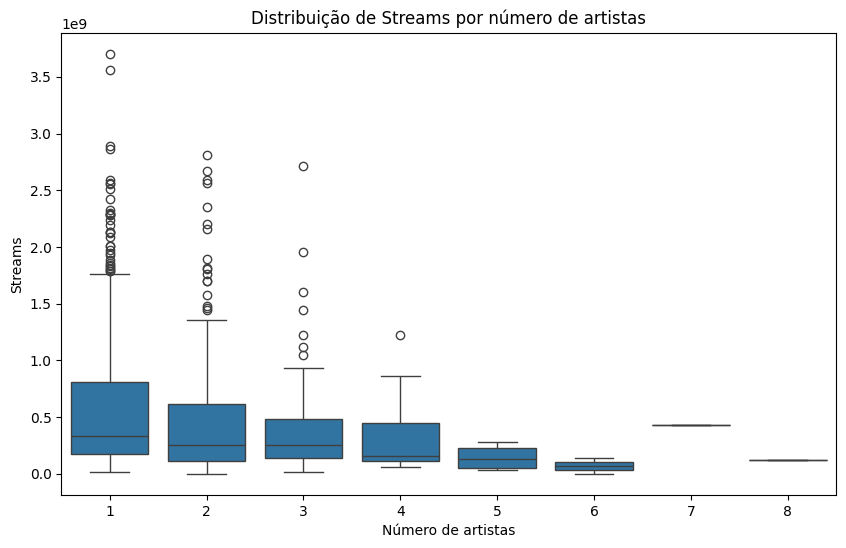

In [0]:
plt.figure(figsize = (10, 6))

sns.boxplot(
    data = df,
    x = 'artist_count',
    y = 'streams'
)

plt.title("Distribuição de Streams por número de artistas")
plt.xlabel("Número de artistas")
plt.ylabel("Streams")
plt.show()

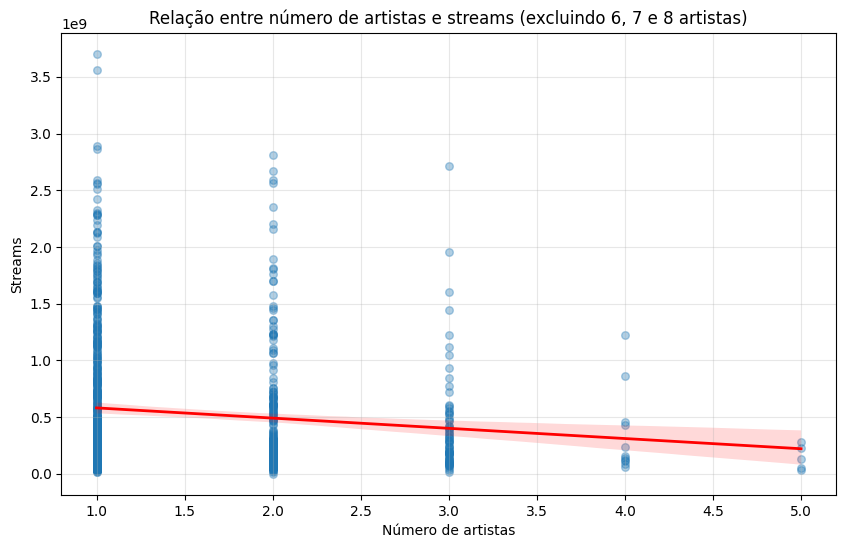

Correlação de Spearman (excluindo 6, 7 e 8 artistas):
              artist_count   streams
artist_count      1.000000 -0.129602
streams          -0.129602  1.000000


In [0]:
# Gráfico de dispersão: artist_count vs streams
# Excluindo artist_count = 6, 7 e 8 (grupos com pouquíssimas observações)

valores_excluidos = [6, 7, 8]

df_filtro_artistas = df[
    ~df['artist_count'].isin(valores_excluidos)
].copy()

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_filtro_artistas,
    x='artist_count',
    y='streams',
    scatter_kws={'alpha': 0.35, 's': 30},
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Relação entre número de artistas e streams (excluindo 6, 7 e 8 artistas)')
plt.xlabel('Número de artistas')
plt.ylabel('Streams')

plt.grid(alpha=0.3)
plt.show()

# Correlação de Spearman com os dados filtrados
print('Correlação de Spearman (excluindo 6, 7 e 8 artistas):')
print(
    df_filtro_artistas[['artist_count', 'streams']]
    .corr(method='spearman')
)

A análise da relação entre a quantidade de artistas participantes de uma música e seu volume de streams apresentou uma correlação de Spearman de 0,13577, indicando uma associação positiva muito fraca entre as variáveis.

Embora a análise descritiva por meio do boxplot tenha indicado medianas de streams menores nos grupos com maior quantidade de artistas, a correlação observada não demonstra uma associação monotônica expressiva.

Para reduzir a influência de grupos com pouquíssimas observações, foi realizada uma análise considerando músicas com até cinco artistas. Essa decisão permite avaliar o comportamento dos grupos com maior representatividade na amostra, mas deve ser considerada uma análise complementar.

Os resultados sugerem que a quantidade de artistas, isoladamente, não apresenta uma associação relevante com o volume acumulado de streams. Portanto, outras características, como gênero musical, popularidade dos artistas, ano de lançamento e presença em playlists, devem ser consideradas para compreender melhor o desempenho das músicas.

In [0]:
df[['artist_count', 'streams']].corr(method='spearman')

,artist_count,streams
artist_count,1.00000,-0.13577
streams,-0.13577,1.00000


#### Análise por Gênero Musical 

In [0]:
#Gênero Musical

analise_genero = (
    df
    .groupby('main_music_genre')['streams']
    .agg(
        quantidade='count',
        media='mean',
        mediana='median'
    )
    .reset_index()
    .sort_values('mediana', ascending=False)
)

display(analise_genero)

main_music_genre,quantidade,media,mediana
Disco pop,1,2.303033973E9,2.303033973E9
Pop punk,1,1.887039593E9,1.887039593E9
EDM,8,1.267081221E9,1.345543491E9
Alternative rock,11,1.0860654936363637E9,1.271293243E9
Indie rock,11,1.174365812909091E9,1.26733335E9
Bachata,1,1.214083358E9,1.214083358E9
New wave,1,1.205951614E9,1.205951614E9
Emo rap,3,1.2249707176666667E9,1.200808494E9
Soul,3,1.035472651E9,1.115880852E9
Pop rock,17,1.0170654656470588E9,1.08568542E9


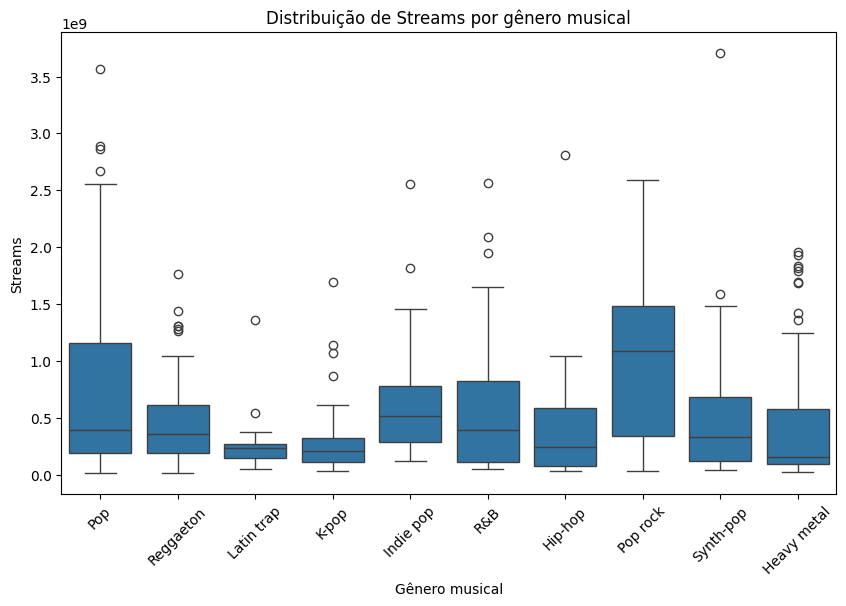

In [0]:
#Visualizar os gêneros mais representativos

top_generos = df['main_music_genre'].value_counts().head(10).index

df_top_generos = df[df['main_music_genre'].isin(top_generos)]

plt.figure(figsize=(10, 6))
sns.boxplot(
    data = df_top_generos,
    x = 'main_music_genre',
    y = 'streams'
)

plt.title('Distribuição de Streams por gênero musical')
plt.xlabel('Gênero musical')
plt.ylabel('Streams')
plt.xticks(rotation=45)
plt.show()




In [0]:
a = df_top_generos[df_top_generos['main_music_genre'] == "Hip-hop"]

a.max()

track_id                                                      8666108
in_apple_playlists                                                372
in_apple_charts                                                   149
in_deezer_playlists                                               843
in_deezer_charts                                                   23
in_shazam_charts                                                  311
track_name                                  What It Is (Solo Version)
artists_name            sped up nightcore, ARIZONATEARS, Lil Uzi Vert
artist_count                                                        5
main_music_genre                                              Hip-hop
main_country                                            United States
released_year                                                    2023
released_month                                                     12
released_day                                                       27
in_spotify_playlists

In [0]:
b = df_top_generos[df_top_generos['main_music_genre'] == "Heavy metal"]

# Identificando os outliers pelo método IQR (mesmo critério do boxplot)
q1 = b['streams'].quantile(0.25)
q3 = b['streams'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers_b = b[b['streams'] > limite_superior]
outliers_b

,track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
106,8189388,80,65,476,0,14,No Role Modelz,J. Cole,1,Heavy metal,United States,2014,12,9,21164,36,1791000570
115,3605651,201,44,6551,2,0,Can't Hold Us (feat. Ray Dalton),"Ray Dalton, Ryan Lewis, Macklemore",3,Heavy metal,United States,2011,8,16,6074,52,1953533826
130,1663974,98,76,3889,5,0,Without Me,Eminem,1,Heavy metal,United States,2002,1,1,21081,43,1687664027
224,2670198,81,53,3271,1,17,The Real Slim Shady,Eminem,1,Heavy metal,United States,2000,1,1,20763,27,1424589568
265,6766942,247,54,5567,1,51,Lose Yourself - Soundtrack Version,Eminem,1,Heavy metal,United States,2002,1,1,32502,21,1829992958
286,5939675,21,0,386,0,<NA>,Gangsta's Paradise,"Coolio, L.V.",2,Heavy metal,United States,1995,7,11,10624,17,1357608774
361,3378211,300,47,690,0,<NA>,INDUSTRY BABY (feat. Jack Harlow),"Jack Harlow, Lil Nas X",2,Heavy metal,United States,2021,7,23,13315,0,1814349763
564,1486311,78,46,2515,1,0,Till I Collapse,"Eminem, Nate Dogg",2,Heavy metal,United States,2002,5,26,22923,0,1695712020
590,5223297,284,114,1481,0,5,HUMBLE.,Kendrick Lamar,1,Heavy metal,United States,2017,3,30,33206,1,1929770265


In [0]:
c = df_top_generos[df_top_generos['main_music_genre'] == "R&B"]

# Identificando os outliers pelo método IQR (mesmo critério do boxplot)
q1 = c['streams'].quantile(0.25)
q3 = c['streams'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers_c = c[c['streams'] > limite_superior]
outliers_c

,track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
45,4367298,281,137,2445,1,140,Starboy,"The Weeknd, Daft Punk",2,R&B,Canada,2016,9,21,29536,79,2565529693
291,6380084,122,94,1992,0,18,The Hills,The Weeknd,1,R&B,Canada,2015,5,27,25744,4,1947371785
547,4152167,308,118,4534,2,77,All of Me,John Legend,1,R&B,United States,2013,8,1,27221,0,2086124197


In [0]:
d = df_top_generos[df_top_generos['main_music_genre'] == "Indie pop"]

# Identificando os outliers pelo método IQR (mesmo critério do boxplot)
q1 = d['streams'].quantile(0.25)
q3 = d['streams'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers_d = d[d['streams'] > limite_superior]
outliers_d

In [0]:
e = df_top_generos[df_top_generos['main_music_genre'] == "Pop"]

# Identificando os outliers pelo método IQR (mesmo critério do boxplot)
q1 = e['streams'].quantile(0.25)
q3 = e['streams'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers_e = e[e['streams'] > limite_superior]
outliers_e

,track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
77,2023156,492,99,798,31,0,STAY (with Justin Bieber),"Justin Bieber, The Kid Laroi",2,Pop,Australia,2021,7,9,17050,36,2665343922
79,8408827,440,125,1800,0,<NA>,Someone You Loved,Lewis Capaldi,1,Pop,United Kingdom,2018,11,8,17836,53,2887241814
164,4299313,33,0,6808,7,0,Shape of You,Ed Sheeran,1,Pop,United Kingdom,2017,1,6,32181,10,3562543890
545,2969661,533,167,3595,6,<NA>,Dance Monkey,Tones and I,1,Pop,Australia,2019,5,10,24529,0,2864791672


In [0]:
f = df_top_generos[df_top_generos['main_music_genre'] == "Reggaeton"]

# Identificando os outliers pelo método IQR (mesmo critério do boxplot)
q1 = f['streams'].quantile(0.25)
q3 = f['streams'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers_f = f[f['streams'] > limite_superior]
outliers_f

,track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
80,3331159,104,120,141,26,49,Me Porto Bonito,"Chencho Corleone, Bad Bunny",2,Reggaeton,Puerto Rico,2022,5,6,8870,43,1440757818
138,3766692,119,81,974,1,503,Danza Kuduro,"Don Omar, Lucenzo",2,Reggaeton,Puerto Rico,2010,1,1,17138,37,1279434863
372,3365981,120,86,164,4,0,Yonaguni,Bad Bunny,1,Reggaeton,Puerto Rico,2021,6,4,9644,28,1260594497
449,4365318,252,109,965,20,<NA>,Pepas,Farruko,1,Reggaeton,Puerto Rico,2021,6,24,14114,17,1309887447
490,3574464,189,166,525,9,25,Dakiti,"Bad Bunny, Jhay Cortez",2,Reggaeton,Puerto Rico,2020,10,30,11215,21,1763363713
689,6990936,162,116,355,7,0,Callaita,"Bad Bunny, Tainy",2,Reggaeton,Puerto Rico,2019,5,31,9539,15,1304313953


In [0]:
g = df_top_generos[df_top_generos['main_music_genre'] == "K-pop"]

# Identificando os outliers pelo método IQR (mesmo critério do boxplot)
q1 = g['streams'].quantile(0.25)
q3 = g['streams'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers_g = g[g['streams'] > limite_superior]
outliers_g

,track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
343,7304378,113,92,259,0,1,Boy With Luv (feat. Halsey),"Halsey, BTS",2,K-pop,South Korea,2019,4,12,4260,0,1065580332
469,2320654,44,109,131,0,<NA>,MONEY,Lisa,1,K-pop,Thailand,2021,9,10,2566,13,863625566
495,8452012,180,135,223,0,5,Butter,BTS,1,K-pop,South Korea,2021,5,21,4779,6,1143647827
499,3745752,239,163,583,0,<NA>,Dynamite,BTS,1,K-pop,South Korea,2020,8,21,8528,5,1692897992


In [0]:
h = df_top_generos[df_top_generos['main_music_genre'] == "Latin trap"]

# Identificando os outliers pelo método IQR (mesmo critério do boxplot)
q1 = h['streams'].quantile(0.25)
q3 = h['streams'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers_h = h[h['streams'] > limite_superior]
outliers_h

,track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
69,4431554,94,65,164,14,176,"Quevedo: Bzrp Music Sessions, Vol. 52","Bizarrap, Quevedo",2,Latin trap,Argentina,2022,7,6,8506,45,1356565093
197,1443757,47,77,53,10,8,La Jumpa,"Arcangel, Bad Bunny",2,Latin trap,Puerto Rico,2022,11,30,3794,34,538115192


In [0]:
top_5_generos = (
    df
    .sort_values('streams', ascending=False)
    .groupby('main_music_genre')
    .head(5)
    [['main_music_genre', 'track_name', 'artists_name', 'streams']]
    .sort_values(
        ['main_music_genre', 'streams'],
        ascending=[True, False]
    )
)

display(top_5_generos)

# Salvar a tabela como 'Top5' no catálogo

# Converter Pandas para Spark DataFrame
df_spark = spark.createDataFrame(top_5_generos)

# Salvar como tabela Delta
(
    df_spark.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("top5generos")
)




main_music_genre,track_name,artists_name,streams
Afrobeats,One Dance,"Drake, WizKid, Kyla",2713922350
Afrobeats,love nwantiti (ah ah ah),Ckay,726837877
Afrobeats,Love Nwantiti - Remix,"Ckay, AX'EL, Dj Yo!",540539717
Afrobeats,People,Libianca,373199958
Afrobeats,Sad Girlz Luv Money Remix (feat. Kali Uchis),"Kali Uchis, Amaarae, Moliy",354065229
Alternative,Softcore,The Neighbourhood,599770206
Alternative,WORTH NOTHING,"Twisted, Oliver Tree",213438580
Alternative,When I R.I.P.,Labrinth,203680270
Alternative,Tormenta (feat. Bad Bunny),"Gorillaz, Bad Bunny",149778242
Alternative,"I'm Tired - From ""Euphoria"" An Original HBO Series",Labrinth,121913181


### Análise das músicas de destaque por gênero musical

Após investigar as diferenças na distribuição de streams entre os gêneros musicais, foi realizada uma análise complementar para identificar as músicas com maior volume de reproduções dentro de cada categoria.

O objetivo foi compreender se os gêneros que apresentam diferenças no comportamento dos streams também possuem músicas que se destacam individualmente, contribuindo para identificar oportunidades de curadoria musical.

Os resultados demonstraram que músicas com volumes expressivos de streams estão distribuídas entre diferentes gêneros. Entre os principais destaques estão *Blinding Lights*, do The Weeknd (Synth-pop), com aproximadamente 3,70 bilhões de streams; *Shape of You*, de Ed Sheeran (Pop), com 3,56 bilhões; *Sunflower*, de Post Malone e Swae Lee (Hip-hop), com 2,81 bilhões; e *One Dance*, de Drake, WizKid e Kyla (Afrobeats), com 2,71 bilhões.

Também foram identificadas faixas de grande alcance em gêneros como Indie pop, Indie rock, EDM, R&B, Pop rock, Reggaeton e K-pop.

A análise evidencia que o gênero musical está associado a diferenças na distribuição de streams, mas que o desempenho individual das músicas também desempenha um papel importante na identificação de sucessos. Desse modo, está descrito, a seguir, as músicas que possuem maior quantidade de streams quando analisadas do ponto de vista da mediana dos gêneros mais significativos e temos disponível também, a tabela 'Top5' com as as cinco músicas que apresentam maior quantidade de streams em seu respectivo grupo musical. 


Análise do gênero musical e seus respectivos streams.

Pop: o bigode superior termina em ~2,55 bi, e há outliers em ~2,7, ~2,9 (dois pontos quase sobrepostos) e ~3,57 bi. Confirma a assimetria positiva: a mediana é ~0,39 bi, mas o gênero contém as músicas mais ouvidas da base. A distância entre a mediana e o topo mostra o quanto poucos hits concentram os streams. Nesse caso, o gênero musical por si só já é suficiente para gerar alta quantidade de streams. Segue as músicas com maiores quantidades de streams:

STAY (with Justin Bieber) - Justin Bieber, The Kid Laroi
Someone You Loved - Lewis Capaldi
Shape of You - Ed Sheeran
Circles - Post Malone
Dance Monkey - Tones and I
Hip-hop: tem um único outlier isolado em 2,8 bi, muito acima do bigode (1,05 bi). Esse ponto sozinho é o maior destaque do gênero e provavelmente é uma música específica de enorme sucesso. Trata-se do sucesso What It Is. Minha sugestão, nesse caso, é sempre que possível incluir essa música nas playlists. Sua presença irá aumentar a quantidade de streams.

R&B: outliers em ~1,95, ~2,08 e ~2,56 bi. O gênero tem mais “hits” do que o primeiro gráfico sugeria. As músicas que geram mais stream são:

Starboy - The Weeknd - Daft Punk
The Hills - The Weeknd
All of Me - John Legend. Minha sugestão, nesse caso, é sempre que possível incluir essas músicas nas playlists. Sua presença irá aumentar a quantidade de streams.
Indie pop: apenas dois outliers (~1,8 e ~2,56 bi). É o gênero com a melhor mediana e poucos casos extremos, ou seja, o desempenho é mais sustentado, não dependente de poucos hits. As músicas que apresentam maior quantidade de streams são:

Another Love - Tom Odell
Heat Waves - Glass Animals

Heavy metal: é o mais surpreendente. Tem a menor mediana (~0,15 bi), mas muitos outliers (cerca de 8 pontos, entre ~1,35 e ~1,95 bi). Isso sugere que a maioria das músicas tem baixo alcance, mas há um grupo de clássicos muito fortes que são:

No Role Modelz, J. Cole.
Can't Hold Us (feat. Ray Dalton) - Ray Dalton, Ryan Lewis, Macklemore
Without Me - Eminem
The Real Slim Shady -Eminem
Lose Yourself - Soundtrack Version - Eminem
Gangsta's Paradise - Coolio, L.V.
INDUSTRY BABY (feat. Jack Harlow) Jack Harlow, Lil Nas X
Till I Collapse Eminem, Nate Dogg
HUMBLE. Kendrick Lamar

Obs: Aqui temos uma questão com relação a base de dados. As músicas:

No Role Modelz — J. Cole
Can't Hold Us — Macklemore, Ryan Lewis e Ray Dalton
Without Me — Eminem
The Real Slim Shady — Eminem
Lose Yourself — Eminem
Gangsta's Paradise — Coolio e L.V.
HUMBLE. — Kendrick Lamar
são predominantemente associadas ao Hip-hop/Rap, não ao Heavy metal.

Reggaeton: vários outliers agrupados entre ~1,25 e ~1,45 bi e um em ~1,75 bi. Isso indica um conjunto de músicas de sucesso, não um caso isolado. Segue as músicas com maiores streams:

Me Porto Bonito - Chencho Corleone, Bad Bunny
Danza Kuduro - Don Omar, Lucenzo
Yonaguni - Bad Bunny
Pepas - Farruko
Dakiti - Bad Bunny, Jhay Cortez
Callaita Bad Bunny, Tainy
K-pop: outliers em ~0,87, ~1,07, ~1,14 e ~1,7 bi, bem acima da caixa (que termina em ~0,32 bi). Caixa estreita com vários hits distantes. Segue as músicas com maiores streams:

Boy With Luv (feat. Halsey) - Halsey, BTS
MONEY - Lisa
Butter - BTS
Dynamite - BTS

Latin trap: a caixa é a mais compacta, com dois outliers (~0,54 e ~1,36 bi). É o gênero mais homogêneo. As músicas com maiores streams são:

Quevedo: Bzrp Music Sessions, Vol. 52 - Bizarrap, Quevedo
La Jumpa - Arcangel, Bad Bunny

In [0]:
#### 4.4.4 Análise por país

In [0]:
%pip install plotly

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 129.8 MB/s  0:00:00
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
#País de origem

# Padronizar códigos de país para nomes completos
mapeamento_paises = {
    'MX': 'Mexico',
    'USA': 'Estados Unidos',
    'PR': 'Porto Rico'
}

df['main_country'] = df['main_country'].replace(mapeamento_paises)

analise_pais = (
    df
    .groupby('main_country')['streams']
    .agg(
        quantidade='count',
        media='mean',
        mediana='median'
    )
    .sort_values('mediana', ascending=False)
    .reset_index()
)

# Nomes em inglês para compatibilidade com o mapa-múndi do Plotly
nomes_mapa = {
    'Estados Unidos': 'United States',
    'Porto Rico': 'Puerto Rico'
}

analise_pais['pais_mapa'] = (
    analise_pais['main_country']
    .map(nomes_mapa)
    .fillna(analise_pais['main_country'])
)

display(analise_pais)

# Mapa-múndi: mediana de streams por país de origem
import plotly.express as px

fig = px.choropleth(
    analise_pais,
    locations='pais_mapa',
    locationmode='country names',
    color='mediana',
    hover_name='main_country',
    hover_data={
        'mediana': ':.2f',
        'media': ':.2f',
        'quantidade': True
    },
    color_continuous_scale='Viridis',
    labels={'mediana': 'Mediana de streams' }
)

fig.update_layout(
    title='Mediana de streams por país de origem - Todos os países',
    geo=dict(showframe=False, showcoastlines=True),
    margin={'l': 0, 'r': 0, 't': 40, 'b': 0}
)

fig.show()

main_country,quantidade,media,mediana,pais_mapa
Ireland,2,1.139871623E9,1.139871623E9,Ireland
Norway,2,1.101079455E9,1.101079455E9,Norway
Netherlands,1,9.91336132E8,9.91336132E8,Netherlands
Belgium,1,9.72509632E8,9.72509632E8,Belgium
Thailand,1,8.63625566E8,8.63625566E8,Thailand
Russia,2,7.692384345E8,7.692384345E8,Russia
Barbados,2,7.661672465E8,7.661672465E8,Barbados
Cuba,1,7.56907987E8,7.56907987E8,Cuba
Armenia,2,7.188370315E8,7.188370315E8,Armenia
Panama,1,6.10045621E8,6.10045621E8,Panama


<!doctype html>

In [0]:
import plotly.express as px

# Filtrar apenas os países com mais de 2 músicas
analise_pais_filtrada = analise_pais[analise_pais['quantidade'] > 5]

fig = px.choropleth(
    analise_pais_filtrada,
    locations='pais_mapa',
    locationmode='country names',
    color='mediana',
    hover_name='main_country',
    hover_data={
        'mediana': ':.2f',
        'media': ':.2f',
        'quantidade': True
    },
    color_continuous_scale='Viridis',
    labels={'mediana': 'Mediana de streams'}
)

fig.update_layout(
    title='Mediana de streams por país de origem - Países com mais de 5 músicas',
    geo=dict(showframe=False, showcoastlines=True),
    margin={'l': 0, 'r': 0, 't': 40, 'b': 0}
)


<!doctype html>

In [0]:
import plotly.express as px

# Filtrar apenas os países com mais de 2 músicas
analise_pais_filtrada = analise_pais[analise_pais['quantidade'] > 10]

fig = px.choropleth(
    analise_pais_filtrada,
    locations='pais_mapa',
    locationmode='country names',
    color='mediana',
    hover_name='main_country',
    hover_data={
        'mediana': ':.2f',
        'media': ':.2f',
        'quantidade': True
    },
    color_continuous_scale='Viridis',
    labels={'mediana': 'Mediana de streams'}
)

fig.update_layout(
    title='Mediana de streams por país de origem - Países com mais de 10 músicas',
    geo=dict(showframe=False, showcoastlines=True),
    margin={'l': 0, 'r': 0, 't': 40, 'b': 0}
)

fig.show()

<!doctype html>

In [0]:
import scikit_posthocs as sp

In [0]:
# Kruskal-Wallis + Dunn incluindo todos os países com n > 10
tab = df.groupby("main_country")['streams'].count()
validos = tab[tab > 10].index
dfp = df[df["main_country"].isin(validos)]

grupos = [g['streams'].dropna().values for _, g in dfp.groupby("main_country")]
H, p = stats.kruskal(*grupos)
k = len(grupos); n = sum(len(g) for g in grupos)
eta2 = (H - k + 1) / (n - k)
print(f"k={k} | n={n} | H={H:.2f} | p={p:.4g} | eta²={eta2:.3f}")

dunn = sp.posthoc_dunn(dfp, val_col='streams', group_col="main_country", p_adjust="holm")
print(dunn.round(4))

k=10 | n=759 | H=65.34 | p=1.24e-10 | eta²=0.075
                Argentina  Australia  Brazil  Canada  Colombia  Mexico  \
Argentina          1.0000     0.1307  1.0000  1.0000    1.0000  1.0000   
Australia          0.1307     1.0000  0.0155  1.0000    0.5029  0.0822   
Brazil             1.0000     0.0155  1.0000  0.1910    1.0000  1.0000   
Canada             1.0000     1.0000  0.1910  1.0000    1.0000  1.0000   
Colombia           1.0000     0.5029  1.0000  1.0000    1.0000  1.0000   
Mexico             1.0000     0.0822  1.0000  1.0000    1.0000  1.0000   
Puerto Rico        0.0857     1.0000  0.0054  1.0000    0.4680  0.0316   
South Korea        1.0000     0.0155  1.0000  0.1226    1.0000  1.0000   
United Kingdom     0.0115     1.0000  0.0004  0.1762    0.0857  0.0021   
United States      0.6916     1.0000  0.0565  1.0000    1.0000  0.3112   

                Puerto Rico  South Korea  United Kingdom  United States  
Argentina            0.0857       1.0000          0.0115      

In [0]:
# Kruskal-Wallis + Dunn incluindo todos os países com n > 10
tab = df.groupby("main_country")['streams'].count()
validos = tab[tab > 5].index
dfp = df[df["main_country"].isin(validos)]

grupos = [g['streams'].dropna().values for _, g in dfp.groupby("main_country")]
H, p = stats.kruskal(*grupos)
k = len(grupos); n = sum(len(g) for g in grupos)
eta2 = (H - k + 1) / (n - k)
print(f"k={k} | n={n} | H={H:.2f} | p={p:.4g} | eta²={eta2:.3f}")

dunn = sp.posthoc_dunn(dfp, val_col='streams', group_col="main_country", p_adjust="holm")
print(dunn.round(4))

k=15 | n=796 | H=76.06 | p=1.511e-10 | eta²=0.079
                Argentina  Australia  Brazil  Canada  Colombia   India  \
Argentina          1.0000     0.3838  1.0000  1.0000     1.000  1.0000   
Australia          0.3838     1.0000  0.0378  1.0000     1.000  0.1356   
Brazil             1.0000     0.0378  1.0000  0.5629     1.000  1.0000   
Canada             1.0000     1.0000  0.5629  1.0000     1.000  1.0000   
Colombia           1.0000     1.0000  1.0000  1.0000     1.000  1.0000   
India              1.0000     0.1356  1.0000  1.0000     1.000  1.0000   
Indonesia          1.0000     1.0000  1.0000  1.0000     1.000  1.0000   
Mexico             1.0000     0.2233  1.0000  1.0000     1.000  1.0000   
Nigeria            1.0000     1.0000  1.0000  1.0000     1.000  1.0000   
Puerto Rico        0.2233     1.0000  0.0117  1.0000     1.000  0.1250   
South Korea        1.0000     0.0387  1.0000  0.3507     1.000  1.0000   
Spain              1.0000     1.0000  1.0000  1.0000     1.000

In [0]:
# Kruskal-Wallis + Dunn incluindo todos os países 
tab = df.groupby("main_country")['streams'].count()
validos = tab.index
dfp = df[df["main_country"].isin(validos)]

grupos = [g['streams'].dropna().values for _, g in dfp.groupby("main_country")]
H, p = stats.kruskal(*grupos)
k = len(grupos); n = sum(len(g) for g in grupos)
eta2 = (H - k + 1) / (n - k)
print(f"k={k} | n={n} | H={H:.2f} | p={p:.4g} | eta²={eta2:.3f}")

dunn = sp.posthoc_dunn(dfp, val_col='streams', group_col="main_country", p_adjust="holm")
print(dunn.round(4))

k=40 | n=841 | H=94.06 | p=1.901e-06 | eta²=0.069
                Argentina  Armenia  Australia  Barbados  Belgium  Brazil  \
Argentina          1.0000      1.0     1.0000       1.0      1.0  1.0000   
Armenia            1.0000      1.0     1.0000       1.0      1.0  1.0000   
Australia          1.0000      1.0     1.0000       1.0      1.0  0.2600   
Barbados           1.0000      1.0     1.0000       1.0      1.0  1.0000   
Belgium            1.0000      1.0     1.0000       1.0      1.0  1.0000   
Brazil             1.0000      1.0     0.2600       1.0      1.0  1.0000   
Cameroon           1.0000      1.0     1.0000       1.0      1.0  1.0000   
Canada             1.0000      1.0     1.0000       1.0      1.0  1.0000   
Chile              1.0000      1.0     1.0000       1.0      1.0  1.0000   
Colombia           1.0000      1.0     1.0000       1.0      1.0  1.0000   
Cuba               1.0000      1.0     1.0000       1.0      1.0  1.0000   
Estados Unidos     1.0000      1.0    

Análise do número de streams por país de origem da música

Para comparar os streams entre países, aplicou-se o teste de Kruskal-Wallis, não paramétrico e adequado à forte assimetria da variável. Como esse teste apenas indica se existe diferença em algum ponto, utilizou-se em seguida o teste post hoc de Dunn com correção de Holm, que identifica quais pares de países diferem. O país refere-se à origem da música, e os rótulos inconsistentes (USA, MX e PR) foram unificados antes da análise. Como o Kruskal-Wallis compara distribuições, os resultados são descritos como tendência a streams maiores ou menores, e não como diferença de medianas.

A análise foi feita em três recortes.

1. Todos os países (Figura 1). Neste recorte, a mediana de streams varia de aproximadamente 0,05 a 1 bilhão, sem padrão regional evidente. Os valores mais extremos, como os da Noruega e da Irlanda, vêm de países com apenas 1 ou 2 músicas na base. Como medianas e testes baseados em amostras tão pequenas são instáveis e pouco poderosos, este recorte tem caráter apenas descritivo, e os testes estatísticos não foram aplicados a ele. Esses países foram excluídos nos recortes seguintes.

2. Países com mais de 10 músicas (Figura 2). O teste de Kruskal-Wallis (k = 10 países; n = 759 músicas) indicou diferença significativa na distribuição de streams (H = 65,34; p < 0,001), com tamanho de efeito médio (η² = 0,075). Isso significa que o país está associado a cerca de 7,5% da variação nos postos de streams, e que a maior parte da variabilidade vem de outros fatores. O teste de Dunn com correção de Holm mostrou que as músicas do Reino Unido tendem a ter mais streams do que as da Coreia do Sul, Brasil, México, Argentina e Estados Unidos (esta última diferença, com p = 0,028, não se manteve no recorte seguinte). Porto Rico difere de Coreia do Sul, Brasil e México, e a Austrália difere de Brasil e Coreia do Sul. A Coreia do Sul também difere dos Estados Unidos. Os demais pares não apresentaram diferença significativa. O destaque da Austrália deve ser lido com cautela, pois ela tem apenas 14 músicas e não difere dos países de posição intermediária.

3. Países com mais de 5 músicas (Figura 3). Este recorte, que inclui 15 países (n = 796 músicas), serviu como análise de sensibilidade. O teste de Kruskal-Wallis permaneceu significativo (H = 76,06; p < 0,001), com tamanho de efeito semelhante ao anterior (η² = 0,079). No teste de Dunn, mantiveram-se significativas as diferenças entre o Reino Unido e Coreia do Sul, Brasil, México e Argentina, entre Porto Rico e Coreia do Sul e Brasil, entre a Austrália e Brasil e Coreia do Sul, e entre a Coreia do Sul e os Estados Unidos. As diferenças entre Reino Unido e Estados Unidos e entre Porto Rico e México, significativas com mais de 10 músicas, deixaram de sê-lo, e devem ser interpretadas como evidência frágil. Surgiu ainda uma diferença entre Índia e Reino Unido, que merece cautela por se basear em apenas 9 músicas indianas. Conclui-se que o padrão principal é robusto ao corte de amostra mínima adotado.

Limitações. O país representa a origem da música, e os streams refletem audiência global. Assim, os resultados descrevem o alcance internacional das faixas de cada país, e não o comportamento dos ouvintes locais. A possível repetição de artistas entre as músicas pode violar a suposição de independência do teste. Além disso, fatores como idioma, gênero musical e ano de lançamento não foram controlados. A análise mostra associação, não causalidade.

Conclusão. Desse modo, a análise mostra que o país de origem de uma música influencia, em parte, o quanto ela é ouvida no Spotify. Músicas do Reino Unido, de Porto Rico e da Austrália tendem a acumular mais streams, enquanto as da Coreia do Sul e do Brasil tendem a acumular menos. Os Estados Unidos e o Canadá ficam numa posição intermediária.

Esse efeito, porém, é moderado: o país explica apenas cerca de 8% da diferença entre as músicas. Os outros 92% dependem de fatores que esta análise não mediu, como artista, idioma, gênero musical e ano de lançamento. Por isso, o país sozinho não deve ser usado para prever o sucesso de uma música.

O que fazer com essa informação:

Usar o país como um critério entre vários, e não como o principal, ao avaliar investimento em artistas ou lançamentos.
Tratar com cautela os países com poucas músicas na base (como a Austrália, com 14 faixas): os resultados são indícios, não certezas.
Não concluir que músicas brasileiras ou sul-coreanas “têm pior desempenho”. Os números medem o alcance internacional das faixas, e muitos artistas desses países têm público forte e fiel em seus mercados locais.
Aprofundar a análise antes de decisões de maior valor, incluindo idioma, gênero e ano de lançamento, por exemplo com um modelo de regressão sobre o logaritmo dos streams, para separar o efeito do país do efeito desses outros fatores.

O que é a dupla Kruskal-Wallis + Dunn

Os dois testes trabalham em sequência e respondem a perguntas diferentes.

1. Kruskal-Wallis (teste global). Pergunta: “os países, no conjunto, se comportam de forma igual em relação aos streams, ou pelo menos um deles é diferente?”

Ele ordena todas as músicas do menor para o maior número de streams, atribui um posto a cada uma (1, 2, 3...) e compara o posto médio de cada país. Se os postos médios forem muito diferentes entre os países, ele rejeita a H₀ (de que todos têm a mesma distribuição). No seu caso: H = 65,34 e p = 1,24 × 10⁻¹⁰, ou seja, existe diferença em algum lugar. Mas ele não diz onde.

2. Dunn (teste post hoc, par a par). Pergunta: “entre quais países, especificamente, está a diferença?”

Ele compara os países dois a dois (Brasil vs. Reino Unido, Austrália vs. Coreia do Sul, etc.) e devolve um p-valor para cada par. Como com 10 países são 45 comparações, a chance de achar “diferença” só por acaso aumenta. Por isso aplicamos a correção de Holm, que ajusta os p-valores para compensar isso. Os valores da matriz que você obteve já são os ajustados; pares com p < 0,05 são os que diferem de fato.

Por que os dois e nessa ordem? O Dunn só faz sentido depois de um Kruskal-Wallis significativo. Primeiro confirma-se que há diferença global; depois localiza-se onde ela está.

In [0]:
%pip install scikit-posthocs

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 152.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-posthocs]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


#### 4.5 Análise do momento do lançamento

Em vez de analisarmos as três variáveis separadamente (ano, mês e dia) vamos construir uma única variável, chamada `release_date`, que representa a data completa de lançamento da música. 

In [0]:
#Vamos construir uma data completa
df_tempo = df.copy()

# Garantir que as variáveis sejam numéricas
colunas_data = [
    'released_year',
    'released_month',
    'released_day'
]

for coluna in colunas_data:
    df_tempo[coluna] = pd.to_numeric(
        df_tempo[coluna],
        errors='coerce'
    )

# Construir a data completa
df_tempo['release_date'] = pd.to_datetime(
    {
        'year': df_tempo['released_year'],
        'month': df_tempo['released_month'],
        'day': df_tempo['released_day']
    },
    errors='coerce'
)

# Verificar quantas datas não puderam ser construídas
print('Datas inválidas ou ausentes:',
      df_tempo['release_date'].isna().sum())

display(
    df_tempo[
        ['released_year', 'released_month',
         'released_day', 'release_date', 'streams']
    ].head()
)

Datas inválidas ou ausentes: 0


released_year,released_month,released_day,release_date,streams
2023,7,14,2023-07-14T00:00:00.000Z,141381703
2023,3,23,2023-03-23T00:00:00.000Z,133716286
2023,6,30,2023-06-30T00:00:00.000Z,140003974
2019,8,23,2019-08-23T00:00:00.000Z,800840817
2023,5,18,2023-05-18T00:00:00.000Z,303236322


In [0]:
#Calcular a correlação de Spearman

from scipy.stats import spearmanr

df_data_completa = df_tempo.dropna(
    subset=['release_date', 'streams']
).copy()

# Converter data para número de dias desde uma data de referência
df_data_completa['release_date_num'] = (
    df_data_completa['release_date'].map(
        lambda data: data.toordinal()
    )
)

correlacao_data, p_valor_data = spearmanr(
    df_data_completa['release_date_num'],
    df_data_completa['streams']
)

print(f'Correlação de Spearman: {correlacao_data:.4f}')
print(f'Valor-p: {p_valor_data:.6f}')
print(f'Quantidade de músicas: {len(df_data_completa)}')

Correlação de Spearman: -0.6713
Valor-p: 0.000000
Quantidade de músicas: 842


A correlação de Spearman encontrada foi de -0.6713, o que representa que existe uma correção forte inversamente proporcional entre a data de lançamento da música e a quantidade de streams. 

In [0]:
#Músicas por ano de lançamento

analise_ano = (
    df_tempo
    .dropna(subset=['released_year', 'streams'])
    .groupby('released_year')['streams']
    .agg(
        quantidade_musicas='count',
        media='mean',
        mediana='median',
        desvio_padrao='std'
    )
    .reset_index()
    .sort_index()
)

display(analise_ano)

released_year,quantidade_musicas,media,mediana,desvio_padrao
1942,1,3.95591396E8,3.95591396E8,null
1946,1,3.89771964E8,3.89771964E8,null
1950,1,4.73248298E8,4.73248298E8,null
1952,1,3.95591396E8,3.95591396E8,null
1957,2,4.59981011E8,4.59981011E8,3.9784734001268554E8
1958,3,4.368543123333333E8,2.95998468E8,2.889433767813768E8
1959,2,2.86708922E8,2.86708922E8,2.258233285955056E8
1963,3,4.370877936666667E8,4.04664135E8,2.1239678161299917E8
1968,1,1.145727611E9,1.145727611E9,null
1971,1,4.60492795E8,4.60492795E8,null


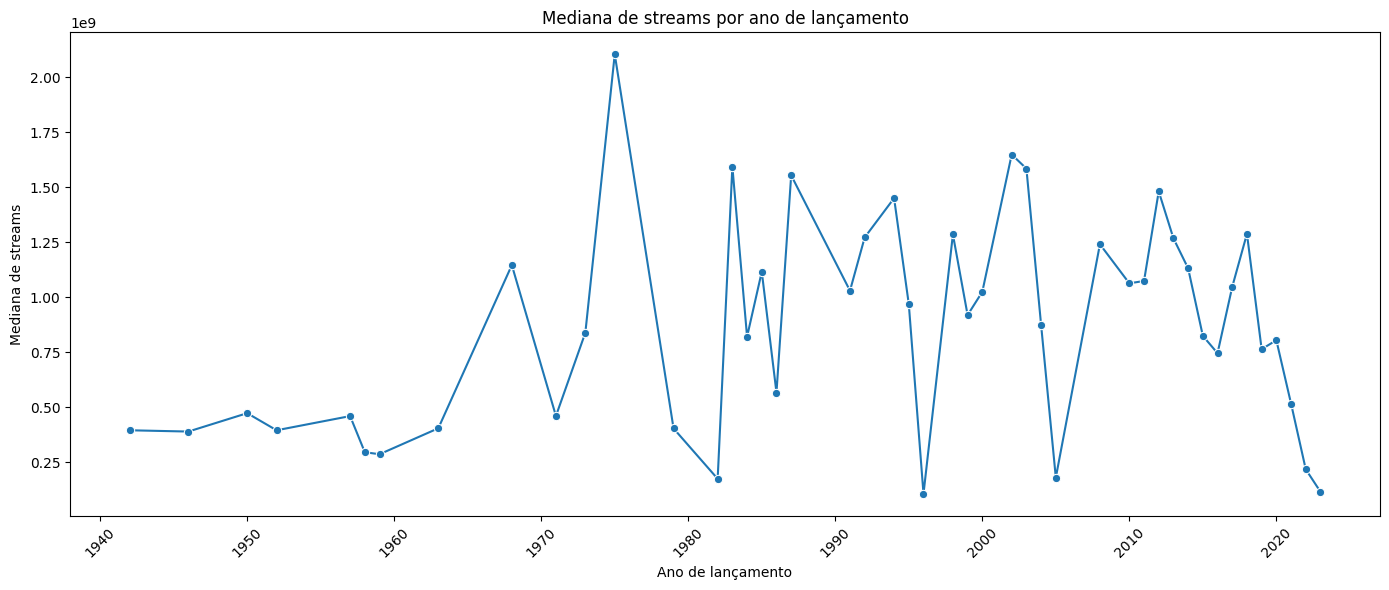

In [0]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=analise_ano.reset_index(),
    x='released_year',
    y='mediana',
    marker='o'
)

plt.title('Mediana de streams por ano de lançamento')
plt.xlabel('Ano de lançamento')
plt.ylabel('Mediana de streams')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [0]:
#Independentemente do ano, existem meses em que as músicas apresentam maiores volumes de streams?

analise_mes = (
    df_tempo
    .dropna(subset=['released_month', 'streams'])
    .groupby('released_month')['streams']
    .agg(
        quantidade_musicas='count',
        media='mean',
        mediana='median'
    )
    .reindex(range(1, 13))
)

display(analise_mes)

quantidade_musicas,media,mediana
117,7.837380602820513E8,6.29173063E8
54,3.729447411111111E8,2.472328255E8
73,5.1481284834246576E8,2.40661097E8
56,4.0978880603571427E8,2.01545267E8
109,4.363978433027523E8,2.36060709E8
78,3.891946029358974E8,1.707940175E8
57,4.926954630877193E8,3.66599607E8
38,6.613621357631578E8,4.26845417E8
50,7.964132729E8,4.860605555E8
65,6.144864430769231E8,3.42779426E8


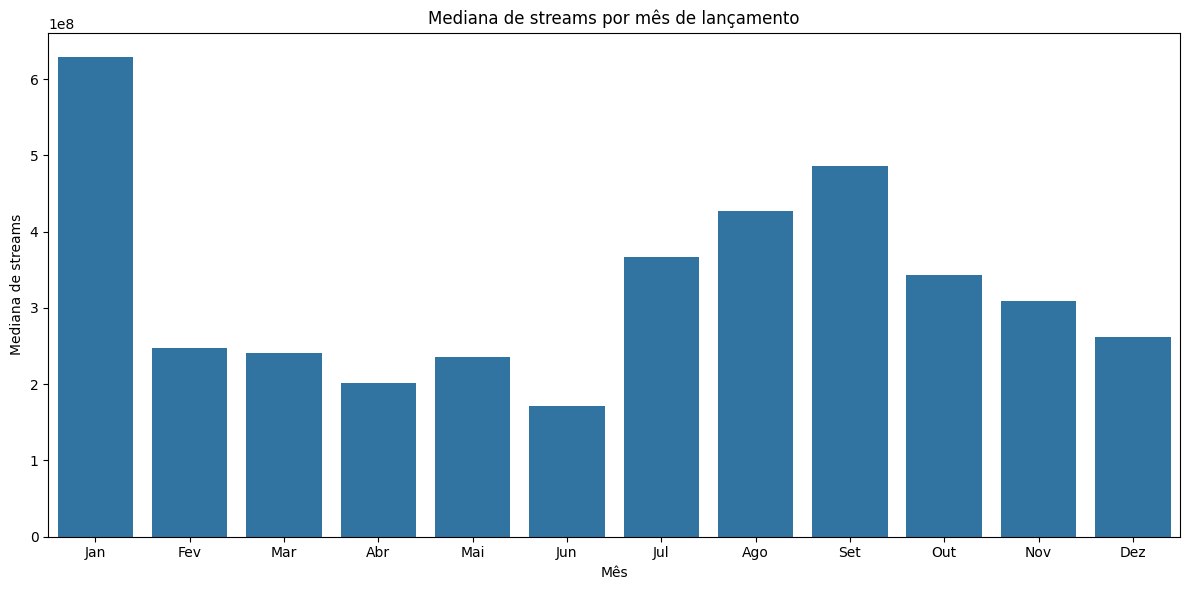

In [0]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=analise_mes.reset_index(),
    x='released_month',
    y='mediana'
)

plt.title('Mediana de streams por mês de lançamento')
plt.xlabel('Mês')
plt.ylabel('Mediana de streams')

plt.xticks(
    range(12),
    ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
     'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
)

plt.tight_layout()
plt.show()

### O momento de lançamento influencia o volume acumulado de streams?

A análise temporal revelou uma associação negativa forte entre a data completa de lançamento e o volume acumulado de streams, com coeficiente de Spearman de -0.6713. Esse resultado reforça a associação inicialmente identificada entre o ano de lançamento e os streams (-0,68).

A interpretação indica que músicas lançadas há mais tempo tendem a apresentar maiores volumes acumulados de reproduções. Uma possível explicação é o maior tempo de exposição nas plataformas de streaming, permitindo que essas músicas acumulem reproduções ao longo de um período mais extenso.

Alguns anos apresentam medianas muito elevadas, enquanto outros apresentam valores consideravelmente menores.

Alguns destaques visuais:
- Décadas de 1940 a 1960: as medianas aparecem relativamente baixas e próximas, em comparação com vários anos posteriores.
- Década de 1970: há um pico bastante expressivo, especialmente em torno de 1975.
- Décadas de 1980 a 2010: encontramos oscilações importantes, com vários anos apresentando medianas acima de 1 bilhão de streams.
- Anos mais recentes: observa-se uma redução das medianas, especialmente nos últimos anos representados.
O gráfico não apresenta uma queda perfeitamente contínua. Existem anos recentes com medianas elevadas e anos anteriores com medianas menores.

Isso é importante porque mostra que a relação negativa encontrada por Spearman representa uma tendência geral, e não uma regra válida para todos os anos.

Na análise por mês, a correlação de Spearman foi de -0.03, indicando ausência de uma tendência monotônica relevante. 

No entanto, janeiro apresenta uma mediana próxima de 627 milhões de streams, enquanto junho apresenta aproximadamente 170 milhões.

Isso sugere que pode haver diferenças entre os meses de lançamento.

Os resultados sugerem que o ano de lançamento apresenta uma associação mais expressiva com o volume acumulado de streams do que o mês e o dia considerados isoladamente. As diferenças observadas entre os meses também merecem investigação, especialmente para verificar possíveis padrões sazonais.


In [0]:
# Converter Pandas para Spark DataFrame
df_spark = spark.createDataFrame(df)

# Salvar como tabela Delta
(
    df_spark.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("tabelaSpotfy")
)

In [0]:
%sql
select * from tabelaspotfy
limit 10

track_id,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,track_name,artists_name,artist_count,main_music_genre,main_country,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams
4082370,43,263,45,10,826,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,Pop,South Korea,2023,7,14,553,147,141381703
6247887,48,126,58,14,382,LALA,Myke Towers,1,Reggaeton,Puerto Rico,2023,3,23,1474,48,133716286
6974739,94,207,91,14,949,vampire,Olivia Rodrigo,1,Pop,United States,2023,6,30,1397,113,140003974
2362023,116,207,125,12,548,Cruel Summer,Taylor Swift,1,Pop,United States,2019,8,23,7858,100,800840817
4386478,84,133,87,15,425,WHERE SHE GOES,Bad Bunny,1,Latin trap,PR,2023,5,18,3133,50,303236322
5031502,67,213,88,17,946,Sprinter,"Dave, Central Cee",2,UK rap,United Kingdom,2023,6,1,2186,91,183706234
1892693,34,222,43,13,418,Ella Baila Sola,"Eslabon Armado, Peso Pluma",2,Regional Mexican,Mexico,2023,3,16,3090,50,725980112
7366228,25,89,30,13,194,Columbia,Quevedo,1,Reggaeton,Spain,2023,7,7,714,43,58149378
5563881,60,210,48,11,953,fukumean,Gunna,1,Trap,United States,2023,5,15,1096,83,95217315
5586506,49,110,66,13,339,La Bebe - Remix,"Peso Pluma, Yng Lvcas",2,Reggaeton,MX,2023,3,17,2953,44,553634067
